# Exercise 4 - Background Removal (GrabCut + Seed Picker)

Classical OpenCV GrabCut only - no deep learning. You click foreground/background seed points (and optionally the ROI rectangle) for each image; **everything is auto-saved to `seeds.json`**. GrabCut, not hand painting, generates the final mask.

**Workflow**
1. Run cells 1-4 (setup, config, segmentation, picker definition).
2. Run `pick_all()` - go through every image, click seeds, press **G** to preview the real GrabCut result, **N** for the next image.
3. Run the batch cell - it reads `seeds.json`, writes masks / transparent PNGs / review figures, and saves the exact settings used for each image next to its outputs.

## 1. Install dependencies
Run once. `PyQt5` is used for the interactive seed-picker window.

In [1]:
%pip install numpy opencv-python matplotlib PyQt5

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Paths and settings

* Input images are loaded from `4 Remove Background/Input`; generated files are written to `4 Remove Background/outputs`.
* `DEFAULTS` - GrabCut parameters shared by all images.
* `INITIAL_SEEDS` - your original seeds. They are only used the **first time** (until an image has an entry in `seeds.json`). After that `seeds.json` is the single source of truth.
* To start an image over: `reset_image("02_red_apple.jpg")`.

In [2]:
from pathlib import Path
import copy, json, time
import cv2
import numpy as np
import matplotlib.pyplot as plt

cv2.setNumThreads(1)

cwd = Path.cwd()
PROJECT_ROOT = next((p for p in (cwd, *cwd.parents) if (p / "4 Remove Background" / "Input").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate the '4 Remove Background' folder.")
IMAGE_DIR  = PROJECT_ROOT / "4 Remove Background" / "Input"
ANSWER_DIR = PROJECT_ROOT / "4 Remove Background"
OUTPUT_DIR = ANSWER_DIR / "outputs"
SEEDS_FILE = ANSWER_DIR / "seeds.json"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_NAMES = [
    "01_yellow_mug.jpg", "02_red_apple.jpg", "03_blue_sneaker.jpg",
    "04_beige_backpack.jpg", "05_potted_fern.jpg",
]

# Shared GrabCut parameters (can be overridden per image inside seeds.json)
DEFAULTS = {"iterations": 5, "inner_margin": 0.020, "seed_radius": 7,
            "seed_iterations": 3, "feather_sigma": 0.8}

# Starting values (only used until the image is saved in seeds.json)
INITIAL_SEEDS = {
    "01_yellow_mug.jpg": {"rectangle": (175, 110, 685, 720),
        "foreground_seeds": [(400, 400), (600, 500), (400, 680), (770, 450)],
        "background_seeds": [(100, 500), (850, 300), (200, 800), (500, 812), (820, 800)]},
    "02_red_apple.jpg": {"rectangle": (260, 120, 500, 670), "inner_margin": 0.025,
        "foreground_seeds": [(500, 450), (420, 550), (600, 600), (500, 250)],
        "background_seeds": [(100, 500), (850, 700), (700, 760), (500, 820), (900, 450)]},
    "03_blue_sneaker.jpg": {"rectangle": (145, 255, 800, 700), "inner_margin": 0.018,
        "foreground_seeds": [(350, 500), (550, 620), (750, 740), (450, 760)],
        "background_seeds": [(100, 200), (500, 280), (900, 300), (170, 880), (900, 850)]},
    "04_beige_backpack.jpg": {"rectangle": (180, 50, 600, 880),
        "foreground_seeds": [(450, 350), (530, 550), (500, 750), (450, 120)],
        "background_seeds": [(100, 450), (190, 500), (770, 500), (500, 940), (900, 800)]},
    "05_potted_fern.jpg": {"rectangle": (30, 40, 940, 920), "inner_margin": 0.010, "feather_sigma": 0.6,
        "foreground_seeds": [(500, 500), (300, 300), (700, 350), (500, 820), (350, 780)],
        "background_seeds": [(100, 100), (900, 100), (900, 900), (100, 900), (500, 970)]},
}


# ---------- persistent seed store (seeds.json) ----------
def _normalize(cfg):
    """Make sure points are tuples and the rectangle is a 4-tuple of ints."""
    cfg = dict(cfg)
    cfg["rectangle"] = tuple(int(v) for v in cfg["rectangle"])
    for key in ("foreground_seeds", "background_seeds"):
        cfg[key] = [tuple(int(v) for v in p) for p in cfg.get(key, [])]
    return cfg

def load_store():
    if SEEDS_FILE.is_file():
        with open(SEEDS_FILE, "r", encoding="utf-8") as f:
            return json.load(f)
    return {}

def save_store(store):
    tmp = SEEDS_FILE.with_suffix(".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(store, f, indent=2)
    tmp.replace(SEEDS_FILE)            # atomic write: never leaves a half-written file

def get_config(name):
    """DEFAULTS + INITIAL_SEEDS, overridden by whatever is saved in seeds.json."""
    if name not in INITIAL_SEEDS and name not in load_store():
        raise KeyError(f"Unknown image: {name}")
    cfg = {**copy.deepcopy(DEFAULTS), **copy.deepcopy(INITIAL_SEEDS.get(name, {}))}
    cfg.update(load_store().get(name, {}))
    return _normalize(cfg)

def save_config(name, cfg):
    store = load_store()
    store[name] = {
        "rectangle": list(cfg["rectangle"]),
        "foreground_seeds": [list(p) for p in cfg["foreground_seeds"]],
        "background_seeds": [list(p) for p in cfg["background_seeds"]],
        **{k: cfg[k] for k in DEFAULTS},
    }
    save_store(store)

def reset_image(name):
    """Forget saved seeds for one image (falls back to INITIAL_SEEDS)."""
    store = load_store()
    store.pop(name, None)
    save_store(store)
    print(f"{name}: reset to initial seeds")

def read_image(name):
    image = cv2.imread(str(IMAGE_DIR / name), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(IMAGE_DIR / name)
    return image

missing = [n for n in IMAGE_NAMES if not (IMAGE_DIR / n).is_file()]
if missing:
    raise FileNotFoundError(f"Missing input images: {missing}")
print(f"Ready: {len(IMAGE_NAMES)} images | seeds file: {SEEDS_FILE}")
for n in IMAGE_NAMES:
    c = get_config(n)
    saved = "saved" if n in load_store() else "initial"
    print(f"  {n:<24} fg={len(c['foreground_seeds'])} bg={len(c['background_seeds'])} [{saved}]")

Ready: 5 images | seeds file: c:\Users\ADMIN\OneDrive\Desktop\Image Processing 1st Project- Ehsan Shafiei\4 Remove Background\seeds.json
  01_yellow_mug.jpg        fg=16 bg=19 [saved]
  02_red_apple.jpg         fg=15 bg=15 [saved]
  03_blue_sneaker.jpg      fg=13 bg=5 [saved]
  04_beige_backpack.jpg    fg=9 bg=5 [saved]
  05_potted_fern.jpg       fg=12 bg=11 [saved]


## 3. GrabCut and transparent output

Seeds only initialise GrabCut (`GC_FGD` / `GC_BGD` disks); the final mask is produced by the algorithm. Foreground seeds that fall outside the ROI are skipped with a warning instead of crashing the run.

In [3]:
def segment_subject(image, config):
    height, width = image.shape[:2]
    x, y, roi_w, roi_h = config["rectangle"]
    if x < 0 or y < 0 or roi_w <= 0 or roi_h <= 0 or x + roi_w > width or y + roi_h > height:
        raise ValueError(f"Invalid GrabCut rectangle for image shape {image.shape}: {config['rectangle']}")

    crop = image[y:y + roi_h, x:x + roi_w]
    margin = max(2, int(min(roi_w, roi_h) * config["inner_margin"]))
    grabcut_rect = (margin, margin, roi_w - 2 * margin, roi_h - 2 * margin)

    mask = np.zeros((roi_h, roi_w), dtype=np.uint8)
    bg_model = np.zeros((1, 65), dtype=np.float64)
    fg_model = np.zeros((1, 65), dtype=np.float64)
    cv2.grabCut(crop, mask, grabcut_rect, bg_model, fg_model, config["iterations"], cv2.GC_INIT_WITH_RECT)

    skipped = []
    def apply_points(points, label):
        for px, py in points:
            lx, ly = int(px - x), int(py - y)
            if 0 <= lx < roi_w and 0 <= ly < roi_h:
                cv2.circle(mask, (lx, ly), config["seed_radius"], int(label), -1)
            elif label == cv2.GC_FGD:
                skipped.append((px, py))      # background outside ROI is already background

    apply_points(config["foreground_seeds"], cv2.GC_FGD)
    apply_points(config["background_seeds"], cv2.GC_BGD)
    if skipped:
        print(f"  warning: {len(skipped)} foreground seed(s) outside the ROI were skipped: {skipped}")

    if config["foreground_seeds"] or config["background_seeds"]:
        cv2.grabCut(crop, mask, None, bg_model, fg_model, config["seed_iterations"], cv2.GC_INIT_WITH_MASK)

    crop_mask = np.where((mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)
    full_mask = np.zeros((height, width), dtype=np.uint8)
    full_mask[y:y + roi_h, x:x + roi_w] = crop_mask
    return full_mask


def make_rgba(image_bgr, mask, feather_sigma):
    alpha = cv2.GaussianBlur(mask, (0, 0), feather_sigma) if feather_sigma > 0 else mask.copy()
    bgra = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2BGRA)
    bgra[:, :, 3] = alpha
    return cv2.cvtColor(bgra, cv2.COLOR_BGRA2RGBA)


def checkerboard(height, width, tile=24):
    yy, xx = np.indices((height, width))
    values = ((xx // tile + yy // tile) % 2) * 55 + 185
    return np.repeat(values[:, :, None], 3, axis=2).astype(np.uint8)


def composite_rgba(rgba, background):
    alpha = rgba[:, :, 3:4].astype(np.float32) / 255.0
    return (rgba[:, :, :3] * alpha + background * (1 - alpha)).astype(np.uint8)

## 4. Seed picker (PyQt5)

One resizable window for **all** images: image list + controls on the right, the image on the left (it scales with the window). `pick_all()` opens it on the first image, `pick_seed_points("02_red_apple.jpg")` opens it on a specific one. **Every change is written to `seeds.json` immediately.**

| Control | Action |
|---|---|
| **F / B / R** (or radio buttons) | foreground (green) / background (red) / ROI rectangle (drag) |
| **Left-click** | add a seed in the current mode |
| **Right-click** | delete the nearest seed |
| **Mouse wheel** | zoom at the cursor |
| **Middle-drag** or **Ctrl+drag** | pan |
| **Home** | fit image to window |
| **U / Ctrl+Z** | undo (points, deletions, rectangle, clears) |
| **G** | live GrabCut preview - runs in a background thread, so the window never freezes |
| **N / P** or arrow keys | next / previous image |
| Parameter boxes | seed radius, iterations, inner margin, feather - saved per image |
| **Save** | save the current image's seeds to `seeds.json` |
| **Exit** | close the picker (the current image is saved before closing) |

Tip: put foreground points deep inside the object, background points on shadows or similar-colour fragments, and keep clicks away from uncertain edges.

In [4]:
import sys
from PyQt5 import QtCore, QtGui, QtWidgets
from PyQt5.QtCore import Qt, QPointF, QRectF, QTimer, QObject, QRunnable, QThreadPool, pyqtSignal

KEY_OF = {"fg": "foreground_seeds", "bg": "background_seeds"}
COLORS = {"fg": QtGui.QColor(0, 220, 0), "bg": QtGui.QColor(235, 40, 40), "rect": QtGui.QColor(255, 200, 0)}


def _np_to_qimage(rgb):
    h, w = rgb.shape[:2]
    return QtGui.QImage(rgb.data, w, h, rgb.strides[0], QtGui.QImage.Format_RGB888)


# ------------------------------------------------------------------ canvas
class Canvas(QtWidgets.QWidget):
    """Resizable image view: click to add seeds, drag for the ROI, wheel = zoom, middle-drag = pan."""
    changed = pyqtSignal()          # cfg was modified -> save it
    message = pyqtSignal(str)

    def __init__(self):
        super().__init__()
        self.setMinimumSize(520, 420)
        self.setMouseTracking(True)
        self.setFocusPolicy(Qt.StrongFocus)
        self.setCursor(Qt.CrossCursor)
        self.cfg = None
        self.qimg = self._rgb = self.overlay = self._ov = None
        self.mode, self.show_overlay, self.overlay_opacity = "fg", False, 0.8
        self.zoom, self.pan = 1.0, QPointF(0, 0)
        self.history = []
        self._drag = self._pan_from = self._hover = None

    # ---- data
    def set_image(self, image_bgr, cfg):
        self._rgb = np.ascontiguousarray(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
        self.qimg = _np_to_qimage(self._rgb)
        self.cfg, self.history = cfg, []
        self.overlay = self._ov = None
        self.fit_view()

    def set_mask(self, mask):
        if mask is None:
            self.overlay = self._ov = None
        else:
            h, w = mask.shape
            arr = np.zeros((h, w, 4), np.uint8)
            arr[mask > 0] = (0, 255, 0, 90)
            arr[mask == 0] = (0, 0, 0, 150)
            self._ov = arr
            self.overlay = QtGui.QImage(arr.data, w, h, 4 * w, QtGui.QImage.Format_RGBA8888)
        self.update()

    def fit_view(self):
        self.zoom, self.pan = 1.0, QPointF(0, 0)
        self.update()

    # ---- geometry
    def _scale(self):
        iw, ih = self.qimg.width(), self.qimg.height()
        return min(self.width() / iw, self.height() / ih) * self.zoom

    def _origin(self):
        s = self._scale()
        return QPointF((self.width() - self.qimg.width() * s) / 2,
                       (self.height() - self.qimg.height() * s) / 2) + self.pan

    def to_img(self, p):
        s, o = self._scale(), self._origin()
        return QPointF((p.x() - o.x()) / s, (p.y() - o.y()) / s)

    def to_view(self, x, y):
        s, o = self._scale(), self._origin()
        return QPointF(o.x() + x * s, o.y() + y * s)

    def _inside(self, pt):
        return 0 <= pt.x() < self.qimg.width() and 0 <= pt.y() < self.qimg.height()

    def _nearest(self, pos, max_dist=14):
        best = None
        for key in KEY_OF.values():
            for i, (x, y) in enumerate(self.cfg[key]):
                v = self.to_view(x, y)
                d = ((v.x() - pos.x()) ** 2 + (v.y() - pos.y()) ** 2) ** 0.5
                if d <= max_dist and (best is None or d < best[0]):
                    best = (d, key, i)
        return best

    # ---- edits (all go through the undo history)
    def add_point(self, key, pt):
        self.cfg[key].append(pt)
        self.history.append(("add", key))
        self.changed.emit()

    def delete_point(self, key, i):
        self.history.append(("del", key, i, self.cfg[key].pop(i)))
        self.changed.emit()

    def set_rect(self, rect):
        self.history.append(("rect", self.cfg["rectangle"]))
        self.cfg["rectangle"] = rect
        self.changed.emit()

    def clear(self, key):
        if self.cfg[key]:
            self.history.append(("clear", key, list(self.cfg[key])))
            self.cfg[key] = []
            self.changed.emit()

    def undo(self):
        if not self.history:
            return self.message.emit("nothing to undo")
        a = self.history.pop()
        if a[0] == "add":     self.cfg[a[1]].pop()
        elif a[0] == "del":   self.cfg[a[1]].insert(a[2], a[3])
        elif a[0] == "rect":  self.cfg["rectangle"] = a[1]
        elif a[0] == "clear": self.cfg[a[1]] = a[2]
        self.changed.emit()

    # ---- events
    @staticmethod
    def _event_pos(e):
        # Keep fractional Qt5 coordinates on high-DPI displays.
        return e.localPos() if hasattr(e, "localPos") else QPointF(e.position())

    def mousePressEvent(self, e):
        if self.qimg is None:
            e.ignore()
            return
        pos = self._event_pos(e)
        if e.button() == Qt.MiddleButton or (e.button() == Qt.LeftButton and e.modifiers() & Qt.ControlModifier):
            self._pan_from = (pos, QPointF(self.pan))
            self.setCursor(Qt.ClosedHandCursor)
            e.accept()
            return
        if e.button() == Qt.RightButton:
            hit = self._nearest(pos)
            if hit:
                self.delete_point(hit[1], hit[2])
                self.message.emit("Deleted nearest seed")
            else:
                self.message.emit("No seed near the pointer")
            e.accept()
            return
        if e.button() != Qt.LeftButton:
            e.ignore()
            return

        pt = self.to_img(pos)
        if self.mode == "rect":
            self._drag = (pt, pt)
            self.message.emit("Drag to draw the ROI rectangle")
        elif not self._inside(pt):
            self.message.emit("Click inside the displayed image to add a seed")
        else:
            p = (int(round(pt.x())), int(round(pt.y())))
            if self.mode == "fg":
                x, y, w, h = self.cfg["rectangle"]
                if not (x <= p[0] < x + w and y <= p[1] < y + h):
                    self.message.emit("Foreground seed is outside the ROI rectangle; choose BG or adjust ROI")
                    e.accept()
                    return
            key = KEY_OF.get(self.mode)
            if key is None:
                self.message.emit(f"Unknown selection mode: {self.mode}")
            else:
                self.add_point(key, p)
                self.message.emit(f"Added {self.mode.upper()} seed at ({p[0]}, {p[1]})")
        e.accept()

    def mouseMoveEvent(self, e):
        if self.qimg is None:
            return
        pos = QPointF(e.pos())
        if self._pan_from:
            self.pan = self._pan_from[1] + (pos - self._pan_from[0])
        elif self._drag:
            self._drag = (self._drag[0], self.to_img(pos))
        else:
            hit = self._nearest(pos)
            self._hover = (hit[1], hit[2]) if hit else None
        self.update()

    def mouseReleaseEvent(self, e):
        if self._pan_from:
            self._pan_from = None; self.setCursor(Qt.CrossCursor); return
        if self._drag and e.button() == Qt.LeftButton:
            (a, b), self._drag = self._drag, None
            W, H = self.qimg.width(), self.qimg.height()
            x1, x2 = sorted((int(max(0, min(W, a.x()))), int(max(0, min(W, b.x())))))
            y1, y2 = sorted((int(max(0, min(H, a.y()))), int(max(0, min(H, b.y())))))
            if x2 - x1 >= 20 and y2 - y1 >= 20:
                self.set_rect((x1, y1, x2 - x1, y2 - y1))
            else:
                self.message.emit("rectangle too small - ignored")
            self.update()

    def wheelEvent(self, e):
        if self.qimg is None:
            return
        pos = QPointF(e.pos())
        before = self.to_img(pos)
        self.zoom = max(0.5, min(12.0, self.zoom * 1.15 ** (e.angleDelta().y() / 120)))
        self.pan += pos - self.to_view(before.x(), before.y())     # keep the point under the cursor fixed
        self.update()

    def leaveEvent(self, e):
        self._hover = None; self.update()

    def paintEvent(self, e):
        p = QtGui.QPainter(self)
        p.setRenderHints(QtGui.QPainter.Antialiasing | QtGui.QPainter.SmoothPixmapTransform)
        p.fillRect(self.rect(), QtGui.QColor(28, 28, 30))
        if self.qimg is None:
            return
        s, o = self._scale(), self._origin()
        target = QRectF(o.x(), o.y(), self.qimg.width() * s, self.qimg.height() * s)
        p.drawImage(target, self.qimg)
        if self.show_overlay and self.overlay is not None:
            p.setOpacity(self.overlay_opacity); p.drawImage(target, self.overlay); p.setOpacity(1.0)

        # ROI rectangle (live while dragging)
        if self._drag:
            a, b = self._drag
            r = QRectF(self.to_view(a.x(), a.y()), self.to_view(b.x(), b.y())).normalized()
        else:
            x, y, w, h = self.cfg["rectangle"]
            r = QRectF(self.to_view(x, y), self.to_view(x + w, y + h))
        p.setPen(QtGui.QPen(COLORS["rect"], 2, Qt.DashLine)); p.setBrush(Qt.NoBrush); p.drawRect(r)

        # seeds
        rad = max(4.0, self.cfg["seed_radius"] * s)
        for mode, key in KEY_OF.items():
            col = COLORS[mode]
            for i, (x, y) in enumerate(self.cfg[key]):
                c = self.to_view(x, y)
                hot = self._hover == (key, i)
                p.setPen(QtGui.QPen(Qt.white if hot else col, 3 if hot else 2))
                p.setBrush(QtGui.QColor(col.red(), col.green(), col.blue(), 70))
                p.drawEllipse(c, rad, rad)
                p.setPen(QtGui.QPen(col, 2))
                p.drawLine(QPointF(c.x() - 6, c.y()), QPointF(c.x() + 6, c.y()))
                p.drawLine(QPointF(c.x(), c.y() - 6), QPointF(c.x(), c.y() + 6))


# ------------------------------------------------------------------ background GrabCut preview
class _Signals(QObject):
    done = pyqtSignal(int, object, str)


class _PreviewJob(QRunnable):
    def __init__(self, ticket, image, cfg, is_current, signals):
        super().__init__()
        self.ticket, self.image, self.cfg = ticket, image, cfg
        self.is_current, self.signals = is_current, signals

    def run(self):
        if not self.is_current():                       # a newer request already replaced this one
            return
        try:
            mask, err = segment_subject(self.image, self.cfg), ""
        except Exception as exc:
            mask, err = None, str(exc)
        self.signals.done.emit(self.ticket, mask, err)


# ------------------------------------------------------------------ main window
class PickerWindow(QtWidgets.QMainWindow):
    def __init__(self, names, start=0):
        super().__init__()
        self.names, self.name, self.image, self.cfg = names, None, None, None
        self.ticket = 0
        self.signals = _Signals(); self.signals.done.connect(self._on_preview_done)
        self.pool = QThreadPool(); self.pool.setMaxThreadCount(1)
        self.timer = QTimer(self, singleShot=True, interval=300)   # debounce: wait until clicks settle
        self.timer.timeout.connect(self._run_preview)
        self.setWindowTitle("GrabCut seed picker")
        self.resize(1280, 820)
        self._build_ui()
        self._build_shortcuts()
        self.list.setCurrentRow(start)

    # ---- UI
    def _build_ui(self):
        self.canvas = Canvas()
        self.canvas.changed.connect(self._commit)
        self.canvas.message.connect(lambda m: self.status.setText(m))

        self.list = QtWidgets.QListWidget()
        self.list.setFixedHeight(150)
        for n in self.names:
            self.list.addItem(n)
        self.list.currentRowChanged.connect(lambda i: i >= 0 and self.load(self.names[i]))

        self.mode_btns = {}
        mode_box = QtWidgets.QGroupBox("Click mode")
        ml = QtWidgets.QVBoxLayout(mode_box)
        for mode, text in (("fg", "Foreground seeds  (F)"), ("bg", "Background seeds  (B)"), ("rect", "ROI rectangle - drag  (R)")):
            b = QtWidgets.QRadioButton(text)
            b.toggled.connect(lambda on, m=mode: on and self.set_mode(m))
            ml.addWidget(b); self.mode_btns[mode] = b
        self.mode_btns["fg"].setChecked(True)

        self.preview_chk = QtWidgets.QCheckBox("Live GrabCut preview  (G)")
        self.preview_chk.toggled.connect(self._toggle_preview)
        self.opacity = QtWidgets.QSlider(Qt.Horizontal, minimum=10, maximum=100, value=80)
        self.opacity.valueChanged.connect(self._set_opacity)
        prev_box = QtWidgets.QGroupBox("Preview")
        pl = QtWidgets.QFormLayout(prev_box)
        pl.addRow(self.preview_chk); pl.addRow("Overlay", self.opacity)

        self.params = {}
        par_box = QtWidgets.QGroupBox("GrabCut parameters (this image)")
        pf = QtWidgets.QFormLayout(par_box)
        for key, label, kind, lo, hi, step in (
                ("seed_radius", "Seed radius (px)", int, 1, 60, 1),
                ("iterations", "Rect iterations", int, 1, 20, 1),
                ("seed_iterations", "Seed iterations", int, 1, 20, 1),
                ("inner_margin", "Inner margin", float, 0.0, 0.2, 0.005),
                ("feather_sigma", "Feather sigma", float, 0.0, 5.0, 0.1)):
            w = QtWidgets.QSpinBox() if kind is int else QtWidgets.QDoubleSpinBox()
            w.setRange(lo, hi); w.setSingleStep(step)
            if kind is float:
                w.setDecimals(3 if key == "inner_margin" else 1)
            w.valueChanged.connect(lambda v, k=key: self._set_param(k, v))
            pf.addRow(label, w); self.params[key] = w

        def button(text, slot):
            b = QtWidgets.QPushButton(text); b.clicked.connect(slot); return b
        edit_box = QtWidgets.QGroupBox("Edit")
        eg = QtWidgets.QGridLayout(edit_box)
        eg.addWidget(button("Undo  (U)", self.canvas.undo), 0, 0, 1, 2)
        eg.addWidget(button("Clear FG", lambda: self.canvas.clear("foreground_seeds")), 1, 0)
        eg.addWidget(button("Clear BG", lambda: self.canvas.clear("background_seeds")), 1, 1)
        eg.addWidget(button("Reset image", self._reset_image), 2, 0)
        eg.addWidget(button("Fit view  (Home)", self.canvas.fit_view), 2, 1)

        nav = QtWidgets.QHBoxLayout()
        nav.addWidget(button("< Prev  (P)", lambda: self.step(-1)))
        nav.addWidget(button("Next >  (N)", lambda: self.step(+1)))
        actions = QtWidgets.QHBoxLayout()
        actions.addWidget(button("Save", self._save_current))
        actions.addWidget(button("Exit", self.close))

        self.counts = QtWidgets.QLabel()
        self.status = QtWidgets.QLabel("Wheel = zoom | middle-drag (or Ctrl+drag) = pan | right-click = delete point")
        self.status.setWordWrap(True)

        side = QtWidgets.QVBoxLayout()
        for w in (self.list, mode_box, prev_box, par_box, edit_box):
            side.addWidget(w)
        side.addLayout(nav); side.addLayout(actions)
        side.addWidget(self.counts); side.addWidget(self.status); side.addStretch(1)
        panel = QtWidgets.QWidget(); panel.setLayout(side); panel.setFixedWidth(310)

        root = QtWidgets.QHBoxLayout()
        root.addWidget(self.canvas, 1); root.addWidget(panel)
        central = QtWidgets.QWidget(); central.setLayout(root)
        self.setCentralWidget(central)

    def _build_shortcuts(self):
        def sc(key, fn):
            QtWidgets.QShortcut(QtGui.QKeySequence(key), self, activated=fn)
        sc("F", lambda: self.mode_btns["fg"].setChecked(True))
        sc("B", lambda: self.mode_btns["bg"].setChecked(True))
        sc("R", lambda: self.mode_btns["rect"].setChecked(True))
        sc("G", self.preview_chk.toggle)
        sc("U", self.canvas.undo); sc("Ctrl+Z", self.canvas.undo)
        sc("N", lambda: self.step(+1)); sc("Right", lambda: self.step(+1))
        sc("P", lambda: self.step(-1)); sc("Left", lambda: self.step(-1))
        sc("Home", self.canvas.fit_view)

    # ---- state
    def set_mode(self, mode):
        self.canvas.mode = mode

    def step(self, d):
        self.list.setCurrentRow(max(0, min(len(self.names) - 1, self.list.currentRow() + d)))

    def load(self, name):
        self.ticket += 1                                  # invalidate any running preview
        self.name, self.image, self.cfg = name, read_image(name), get_config(name)
        save_config(name, self.cfg)                       # make sure the image has an entry in seeds.json
        self.canvas.set_image(self.image, self.cfg)
        for key, w in self.params.items():
            w.blockSignals(True); w.setValue(self.cfg[key]); w.blockSignals(False)
        self._refresh_labels()
        self.status.setText(f"Loaded {name}")
        if self.preview_chk.isChecked():
            self._run_preview()

    def _commit(self):
        """Any edit: auto-save to seeds.json, refresh labels, schedule the preview."""
        self.cfg = self.canvas.cfg
        save_config(self.name, self.cfg)
        self._refresh_labels()
        x, y, w, h = self.cfg["rectangle"]
        outside = sum(not (x <= px < x + w and y <= py < y + h) for px, py in self.cfg["foreground_seeds"])
        self.status.setText(f"saved  |  {outside} foreground seed(s) outside the rectangle (will be skipped)" if outside else "saved")
        self.canvas.update()
        if self.preview_chk.isChecked():
            self.timer.start()

    def _save_current(self):
        self.cfg = self.canvas.cfg
        save_config(self.name, self.cfg)
        self.status.setText(f"Saved to {SEEDS_FILE}")

    def _set_param(self, key, value):
        self.cfg[key] = value
        self._commit()

    def _refresh_labels(self):
        c = self.cfg
        self.counts.setText(f"fg: {len(c['foreground_seeds'])}   bg: {len(c['background_seeds'])}   ROI: {tuple(c['rectangle'])}")
        item = self.list.item(self.names.index(self.name))
        item.setText(f"{self.name}   (fg {len(c['foreground_seeds'])} / bg {len(c['background_seeds'])})")

    def _reset_image(self):
        if QtWidgets.QMessageBox.question(self, "Reset", f"Reset {self.name} to its initial seeds?") \
                == QtWidgets.QMessageBox.Yes:
            reset_image(self.name)
            self.load(self.name)

    # ---- preview
    def _toggle_preview(self, on):
        self.canvas.show_overlay = on
        if on:
            self._run_preview()
        else:
            self.ticket += 1; self.timer.stop(); self.status.setText("preview off")
        self.canvas.update()

    def _set_opacity(self, v):
        self.canvas.overlay_opacity = v / 100; self.canvas.update()

    def _run_preview(self):
        self.ticket += 1
        t = self.ticket
        self.status.setText("running GrabCut...")
        self.pool.start(_PreviewJob(t, self.image, copy.deepcopy(self.cfg), lambda: t == self.ticket, self.signals))

    def _on_preview_done(self, ticket, mask, err):
        if ticket != self.ticket:                         # stale result
            return
        self.status.setText(f"preview error: {err}" if err else "preview updated")
        self.canvas.set_mask(mask)

    def closeEvent(self, e):
        self.ticket += 1
        if self.name:
            save_config(self.name, self.cfg)
        self.pool.waitForDone(5000)
        super().closeEvent(e)


# ------------------------------------------------------------------ entry points
_WINDOW = None

def open_picker(names=None, start=0):
    """Open the picker window; blocks until it is closed. Everything is auto-saved to seeds.json."""
    global _WINDOW
    app = QtWidgets.QApplication.instance() or QtWidgets.QApplication(sys.argv[:1])
    app.setStyle("Fusion")
    _WINDOW = PickerWindow(list(names or IMAGE_NAMES), start)
    _WINDOW.show(); _WINDOW.raise_(); _WINDOW.activateWindow()
    app.exec_()
    print("Picker closed. Seeds are stored in", SEEDS_FILE)
    for n in IMAGE_NAMES:
        c = get_config(n)
        print(f"  {n:<24} fg={len(c['foreground_seeds'])} bg={len(c['background_seeds'])} rect={c['rectangle']}")


def pick_seed_points(image_name):
    """Open the picker on one image (you can still switch images inside the window)."""
    open_picker(IMAGE_NAMES, IMAGE_NAMES.index(image_name))


def pick_all(start=0, names=None):
    """Open the picker on the first image."""
    open_picker(names or IMAGE_NAMES, start)

## 5. Choose seeds for every image
Run this, click through all five images, then continue to the next cell. You can re-run it any time - it always starts from what is saved.

In [5]:
pick_all()

Picker closed. Seeds are stored in c:\Users\ADMIN\OneDrive\Desktop\Image Processing 1st Project- Ehsan Shafiei\4 Remove Background\seeds.json
  01_yellow_mug.jpg        fg=16 bg=19 rect=(85, 66, 782, 877)
  02_red_apple.jpg         fg=15 bg=15 rect=(260, 120, 500, 670)
  03_blue_sneaker.jpg      fg=13 bg=5 rect=(145, 255, 800, 700)
  04_beige_backpack.jpg    fg=9 bg=5 rect=(180, 50, 600, 880)
  05_potted_fern.jpg       fg=12 bg=11 rect=(30, 40, 940, 920)


## 6. Run GrabCut for all images

Reads the saved seeds, writes for every image:
`<stem>_mask.png`, `<stem>_transparent.png`, `<stem>_review.png` and **`<stem>_seeds_used.json`** (the exact rectangle, seeds and parameters used for that output).
Set `ONLY = ["02_red_apple.jpg"]` to re-run a single image.

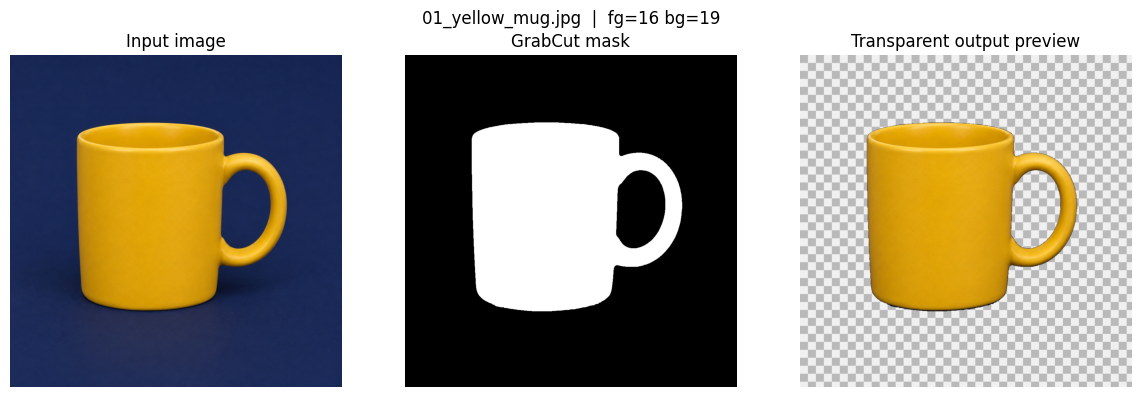

01_yellow_mug.jpg: done in 12.3s | foreground = 26.4% of image


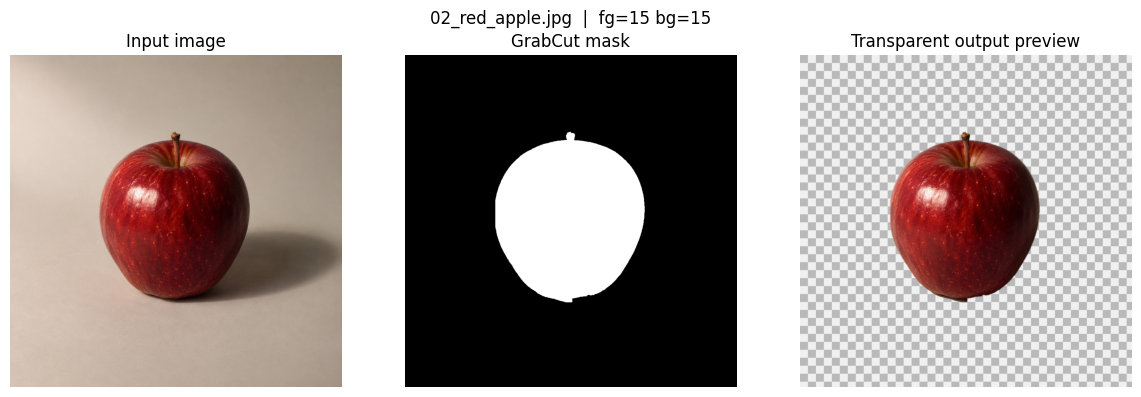

02_red_apple.jpg: done in 2.8s | foreground = 17.2% of image


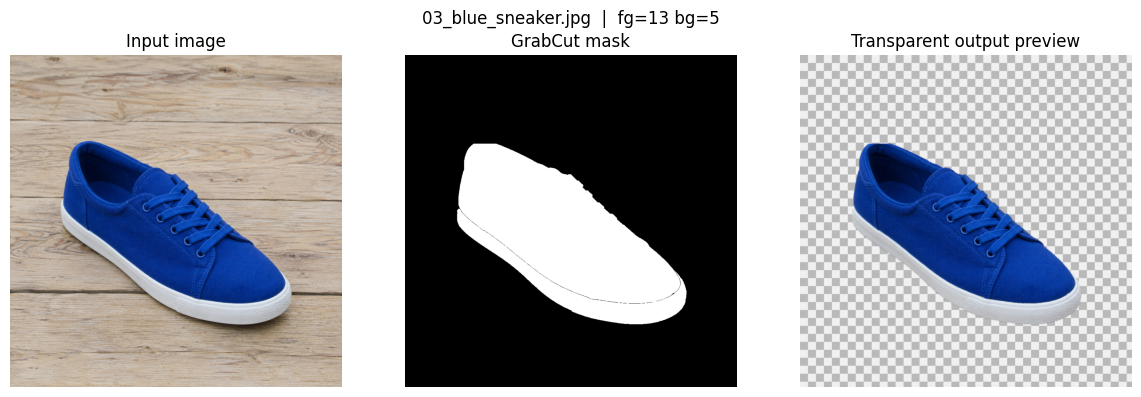

03_blue_sneaker.jpg: done in 9.8s | foreground = 21.0% of image


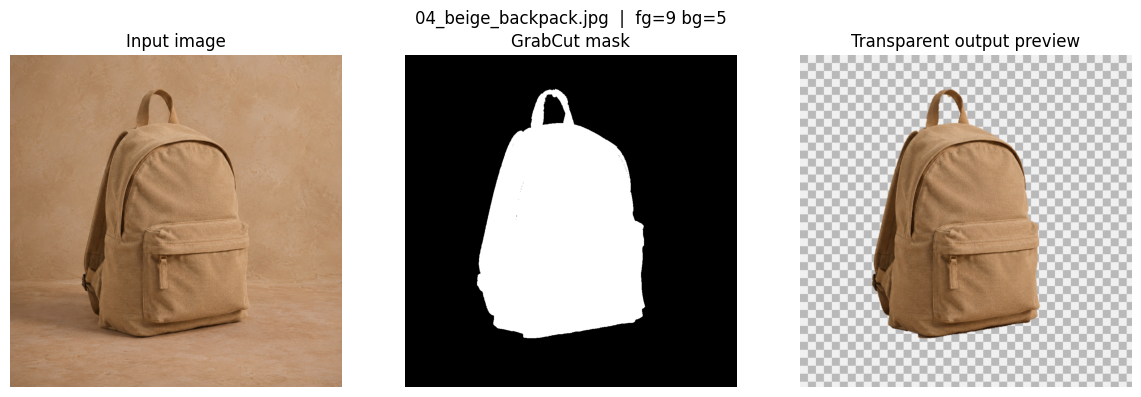

04_beige_backpack.jpg: done in 8.1s | foreground = 26.9% of image


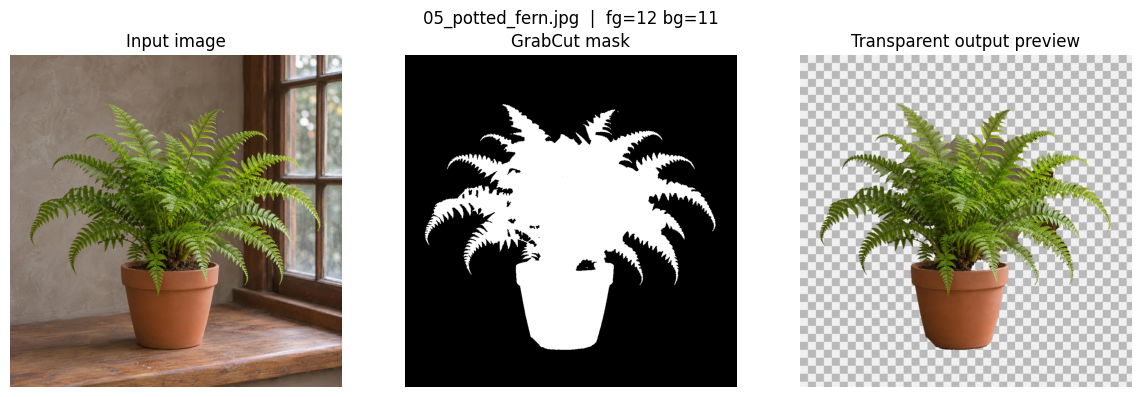

05_potted_fern.jpg: done in 16.1s | foreground = 26.6% of image

Saved masks, transparent PNGs, review figures and seed records to c:\Users\ADMIN\OneDrive\Desktop\Image Processing 1st Project- Ehsan Shafiei\4 Remove Background\outputs


In [6]:
ONLY = None          # e.g. ["02_red_apple.jpg"] to re-run only some images

def process_image(name, show=True):
    image = read_image(name)
    cfg = get_config(name)
    t0 = time.time()
    mask = segment_subject(image, cfg)
    rgba = make_rgba(image, mask, cfg["feather_sigma"])
    stem = Path(name).stem

    cv2.imwrite(str(OUTPUT_DIR / f"{stem}_mask.png"), mask)
    cv2.imwrite(str(OUTPUT_DIR / f"{stem}_transparent.png"), cv2.cvtColor(rgba, cv2.COLOR_RGBA2BGRA))
    with open(OUTPUT_DIR / f"{stem}_seeds_used.json", "w", encoding="utf-8") as f:
        json.dump({"image": name, **{k: (list(v) if k == "rectangle" else v) for k, v in cfg.items()}},
                  f, indent=2)

    preview = composite_rgba(rgba, checkerboard(*mask.shape))
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)); axes[0].set_title("Input image")
    axes[1].imshow(mask, cmap="gray", vmin=0, vmax=255);    axes[1].set_title("GrabCut mask")
    axes[2].imshow(preview);                                axes[2].set_title("Transparent output preview")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(f"{name}  |  fg={len(cfg['foreground_seeds'])} bg={len(cfg['background_seeds'])}")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{stem}_review.png", dpi=120, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)
    print(f"{name}: done in {time.time() - t0:.1f}s | foreground = {100 * (mask > 0).mean():.1f}% of image")
    return {"image": image, "mask": mask, "rgba": rgba}

results = {name: process_image(name) for name in (ONLY or IMAGE_NAMES)}
print(f"\nSaved masks, transparent PNGs, review figures and seed records to {OUTPUT_DIR}")

## Submission outputs

For each image `outputs/` contains the generated binary mask, the transparent RGBA PNG, the side-by-side review figure and a `_seeds_used.json` record. The global `seeds.json` holds the latest seeds for all images. Classical GrabCut is sensitive to shadows, similar colours and fine fern leaves, so inspect every result and refine seeds with `pick_seed_points(name)` + the batch cell if needed.